# BIOT 6900 · Module 8 — Single-Cell Transcriptomics
## Toy notebook (1 of 3): the PBMC 3k workflow, start to finish

**This is a run-and-read notebook. There is no code for you to write.** Open it in Jupyter inside your `biot6900` environment, run **Kernel → Restart & Run All**, and read the explanation above each cell as the output appears.

It walks the entire single-cell pipeline from the lecture on a small, clean, **real** dataset so you can watch the machinery work before you drive it yourself in the next two notebooks.

- **Dataset:** 2,700 peripheral blood mononuclear cells (PBMCs), real 10x Genomics public data. *This is real data, not a simulation.*
- **Maps to:** LO1 (apply industry-standard tools), LO3 (interpret results biologically).
- **The question we are building toward:** given a gene, *which cells* express it? Bulk cannot say. By the last cell, you will.

> Toy (this notebook) → Real data (COVID-19 PBMCs + scVI, on the HPC cluster) → Your own disease (the graded assignment). Same method each time.

### Before you run

- Use the course `biot6900` conda environment.
- Required packages: `scanpy`, `leidenalg`, `python-igraph` (plus `numpy`, `pandas`, `matplotlib`, `scikit-learn`, already in the env). If a `import scanpy` fails, run the install cell once, then restart the kernel.
- The first run downloads the PBMC 3k dataset (~5 MB) and caches it under `./data/`. You need internet for that first run only.

In [21]:
# Run once if scanpy is not already installed in your biot6900 env, then restart the kernel.
# %pip install scanpy leidenalg igraph

In [22]:
import scanpy as sc
import anndata as ad
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sc.settings.verbosity = 1                      # print the main steps as they run
sc.settings.set_figure_params(dpi=80, facecolor="white")
print("scanpy", sc.__version__, "| anndata", ad.__version__)

scanpy 1.11.5 | anndata 0.12.19


/var/folders/cs/q9v9wry90sld3yrkbx9l1l1m0000gn/T/ipykernel_87103/2155897202.py:9: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  print("scanpy", sc.__version__, "| anndata", ad.__version__)
/var/folders/cs/q9v9wry90sld3yrkbx9l1l1m0000gn/T/ipykernel_87103/2155897202.py:9: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  print("scanpy", sc.__version__, "| anndata", ad.__version__)


## Step 1 · Load the data

`sc.datasets.pbmc3k()` returns an `AnnData` object: a **cells × genes** count matrix plus metadata. Note the shape and, especially, the **sparsity** — most entries are zero. That dropout is the defining property of single-cell data, and it is why several later steps exist.

In [23]:
adata = sc.datasets.pbmc3k()      # real 10x Genomics PBMC data (downloads + caches on first run)
adata.var_names_make_unique()

n_cells, n_genes = adata.shape
nz = adata.X.nnz if hasattr(adata.X, "nnz") else np.count_nonzero(adata.X)
sparsity = 1.0 - nz / (n_cells * n_genes)
print(adata)
print(f"\n{n_cells:,} cells  ×  {n_genes:,} genes")
print(f"fraction of matrix that is zero (dropout): {sparsity:.1%}")

AnnData object with n_obs × n_vars = 2700 × 32738
    var: 'gene_ids'

2,700 cells  ×  32,738 genes
fraction of matrix that is zero (dropout): 97.4%


## Step 2 · Quality control — garbage in, garbage out

Every downstream cluster inherits these filtering decisions, so QC is where interpretation starts, not a rote preamble. We look at three signals per cell:

- **genes per cell** — too few means an empty droplet or a dying cell; too many hints at a **doublet** (two cells in one droplet).
- **total counts** — library size per cell.
- **% mitochondrial reads** — a high fraction flags a stressed or dying cell whose cytoplasmic RNA has leaked away.

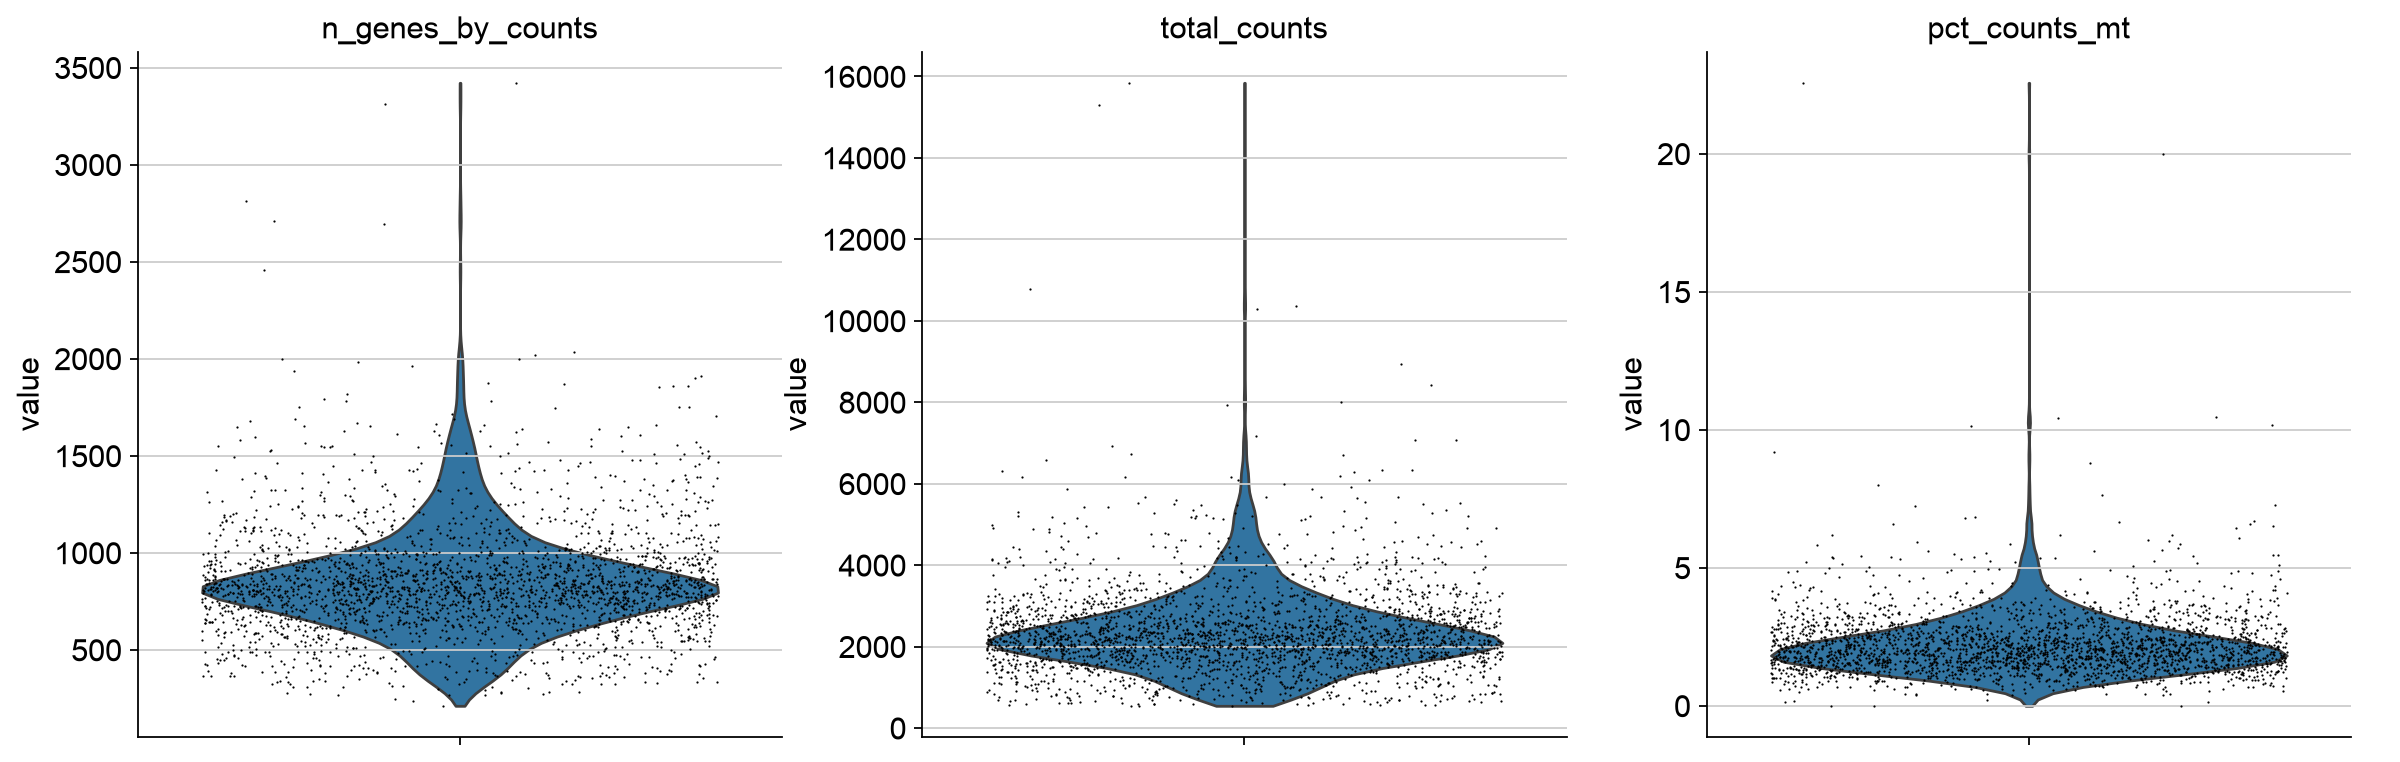

In [24]:
adata.var["mt"] = adata.var_names.str.startswith("MT-")   # mitochondrial genes
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], percent_top=None, log1p=False, inplace=True)

sc.pl.violin(adata, ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
             jitter=0.4, multi_panel=True)

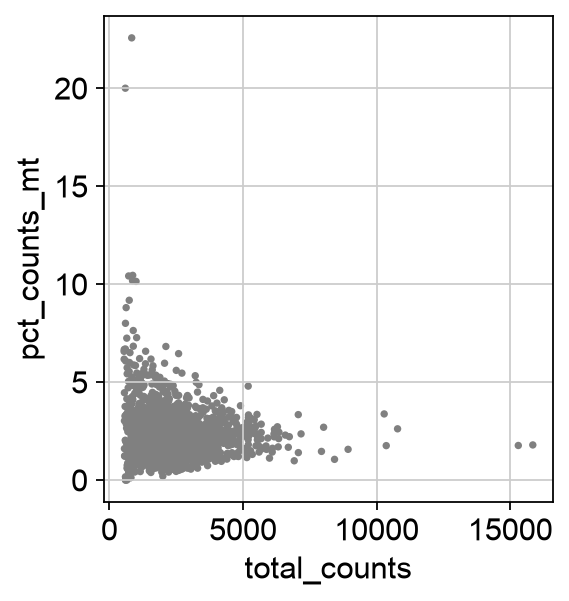

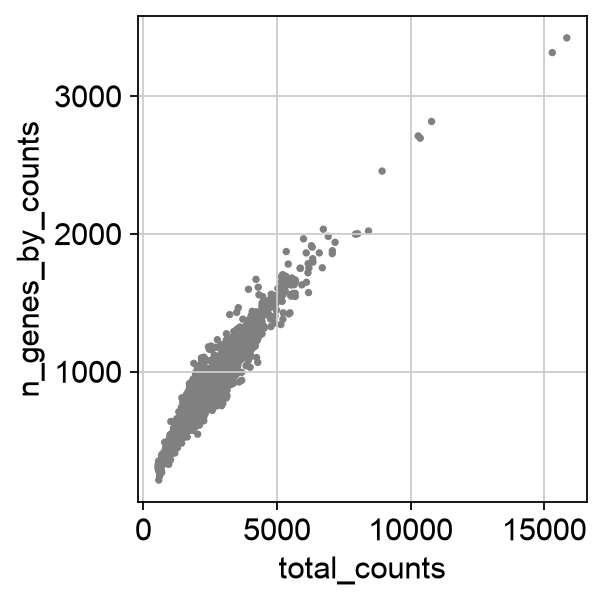

In [25]:
sc.pl.scatter(adata, x="total_counts", y="pct_counts_mt")
sc.pl.scatter(adata, x="total_counts", y="n_genes_by_counts")

Now apply the filters. We drop cells with very few genes, genes seen in almost no cells, and cells that look dead (too many genes = likely doublets; high mitochondrial %). Watch the cell count fall.

In [26]:
before = adata.n_obs
sc.pp.filter_cells(adata, min_genes=200)     # a cell must express >= 200 genes
sc.pp.filter_genes(adata, min_cells=3)       # a gene must appear in >= 3 cells

adata = adata[(adata.obs.n_genes_by_counts < 2500) & (adata.obs.pct_counts_mt < 5)].copy()
print(f"cells before QC: {before:,}")
print(f"cells after  QC: {adata.n_obs:,}")

cells before QC: 2,700
cells after  QC: 2,638


## Step 3 · Normalize and log-transform

Cells differ in how deeply they were sequenced. Normalizing each cell to the same total, then taking `log1p`, puts every cell on a comparable scale and tames the long tail of highly expressed genes. After this, "expression" is a log-normalized value, not a raw count.

In [27]:
sc.pp.normalize_total(adata, target_sum=1e4)   # each cell summed to 10,000 counts
sc.pp.log1p(adata)                             # log(1 + x)

## Step 4 · Keep the informative genes

Most genes carry no useful variation (housekeeping, noise). **Highly variable genes (HVGs)** are the ~2,000 that actually vary across cells — the ones that will separate cell types. We stash the full log-normalized matrix in `adata.raw` first (we will need every gene later for marker plots), then restrict the working matrix to HVGs.

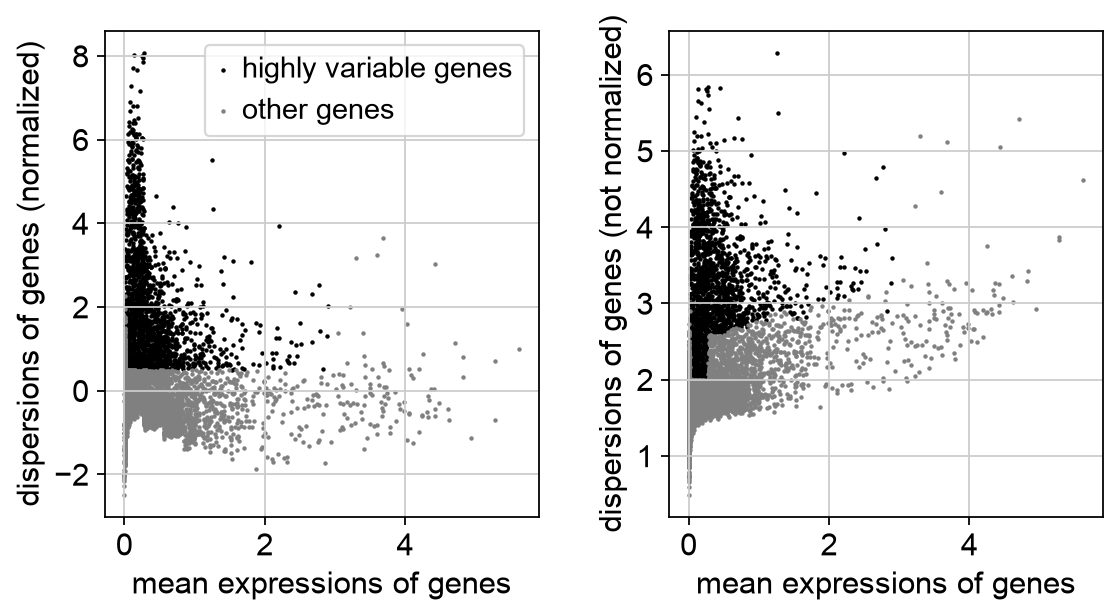

genes kept as highly variable: 1,838


In [28]:
sc.pp.highly_variable_genes(adata, min_mean=0.0125, max_mean=3, min_disp=0.5)
sc.pl.highly_variable_genes(adata)

adata.raw = adata                              # keep all genes (log-normalized) for later
adata = adata[:, adata.var.highly_variable].copy()
print(f"genes kept as highly variable: {adata.n_vars:,}")

## Step 5 · Scale, then compress with PCA

Scaling gives each gene equal footing. **PCA** then compresses thousands of genes into a few dozen components that capture the real structure, which makes the next steps fast and denoised. The variance-ratio plot shows how many components are worth keeping (the curve flattens).

/opt/anaconda3/envs/biot6900/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


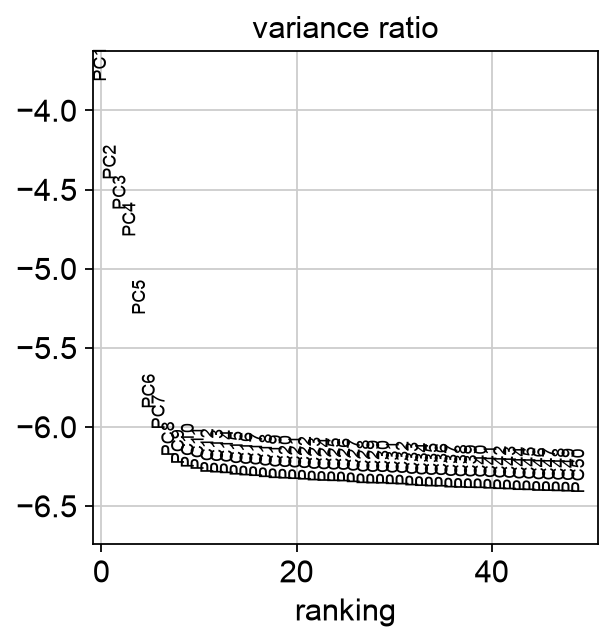

In [29]:
sc.pp.scale(adata, max_value=10)
sc.tl.pca(adata, svd_solver="arpack")
sc.pl.pca_variance_ratio(adata, n_pcs=50, log=True)

## Step 6 · Build the neighbor graph, embed, and cluster

We link each cell to its nearest neighbors in PCA space, lay that graph out in 2-D with **UMAP**, and cut it into communities with **Leiden** — those communities are our clusters.

> **UMAP is for looking, not measuring.** It is a 2-D cartoon of high-dimensional structure. Distances between clusters, and the sizes and shapes of clusters, are **not** meaningful. Use it to *see* groups; never to quantify them.

In [30]:
sc.pp.neighbors(adata, n_neighbors=10, n_pcs=40)
sc.tl.umap(adata)

# Leiden call is written to work across scanpy versions:
try:
    sc.tl.leiden(adata, resolution=0.5, flavor="igraph", n_iterations=2,
                 directed=False, random_state=0)
except TypeError:
    sc.tl.leiden(adata, resolution=0.5, random_state=0)

print("clusters found:", adata.obs["leiden"].nunique())

clusters found: 6


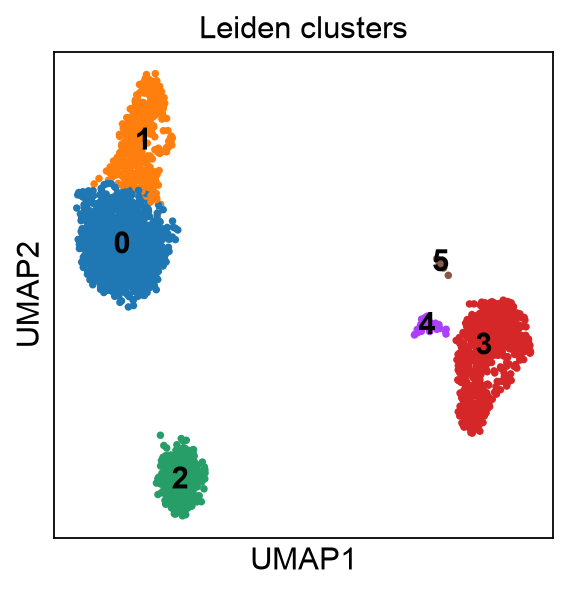

In [31]:
sc.pl.umap(adata, color="leiden", legend_loc="on data", title="Leiden clusters")

## Step 7 · What defines each cluster?

`rank_genes_groups` finds the genes most enriched in each cluster versus the rest. These data-driven markers are what you reason from — not a label you assumed in advance.

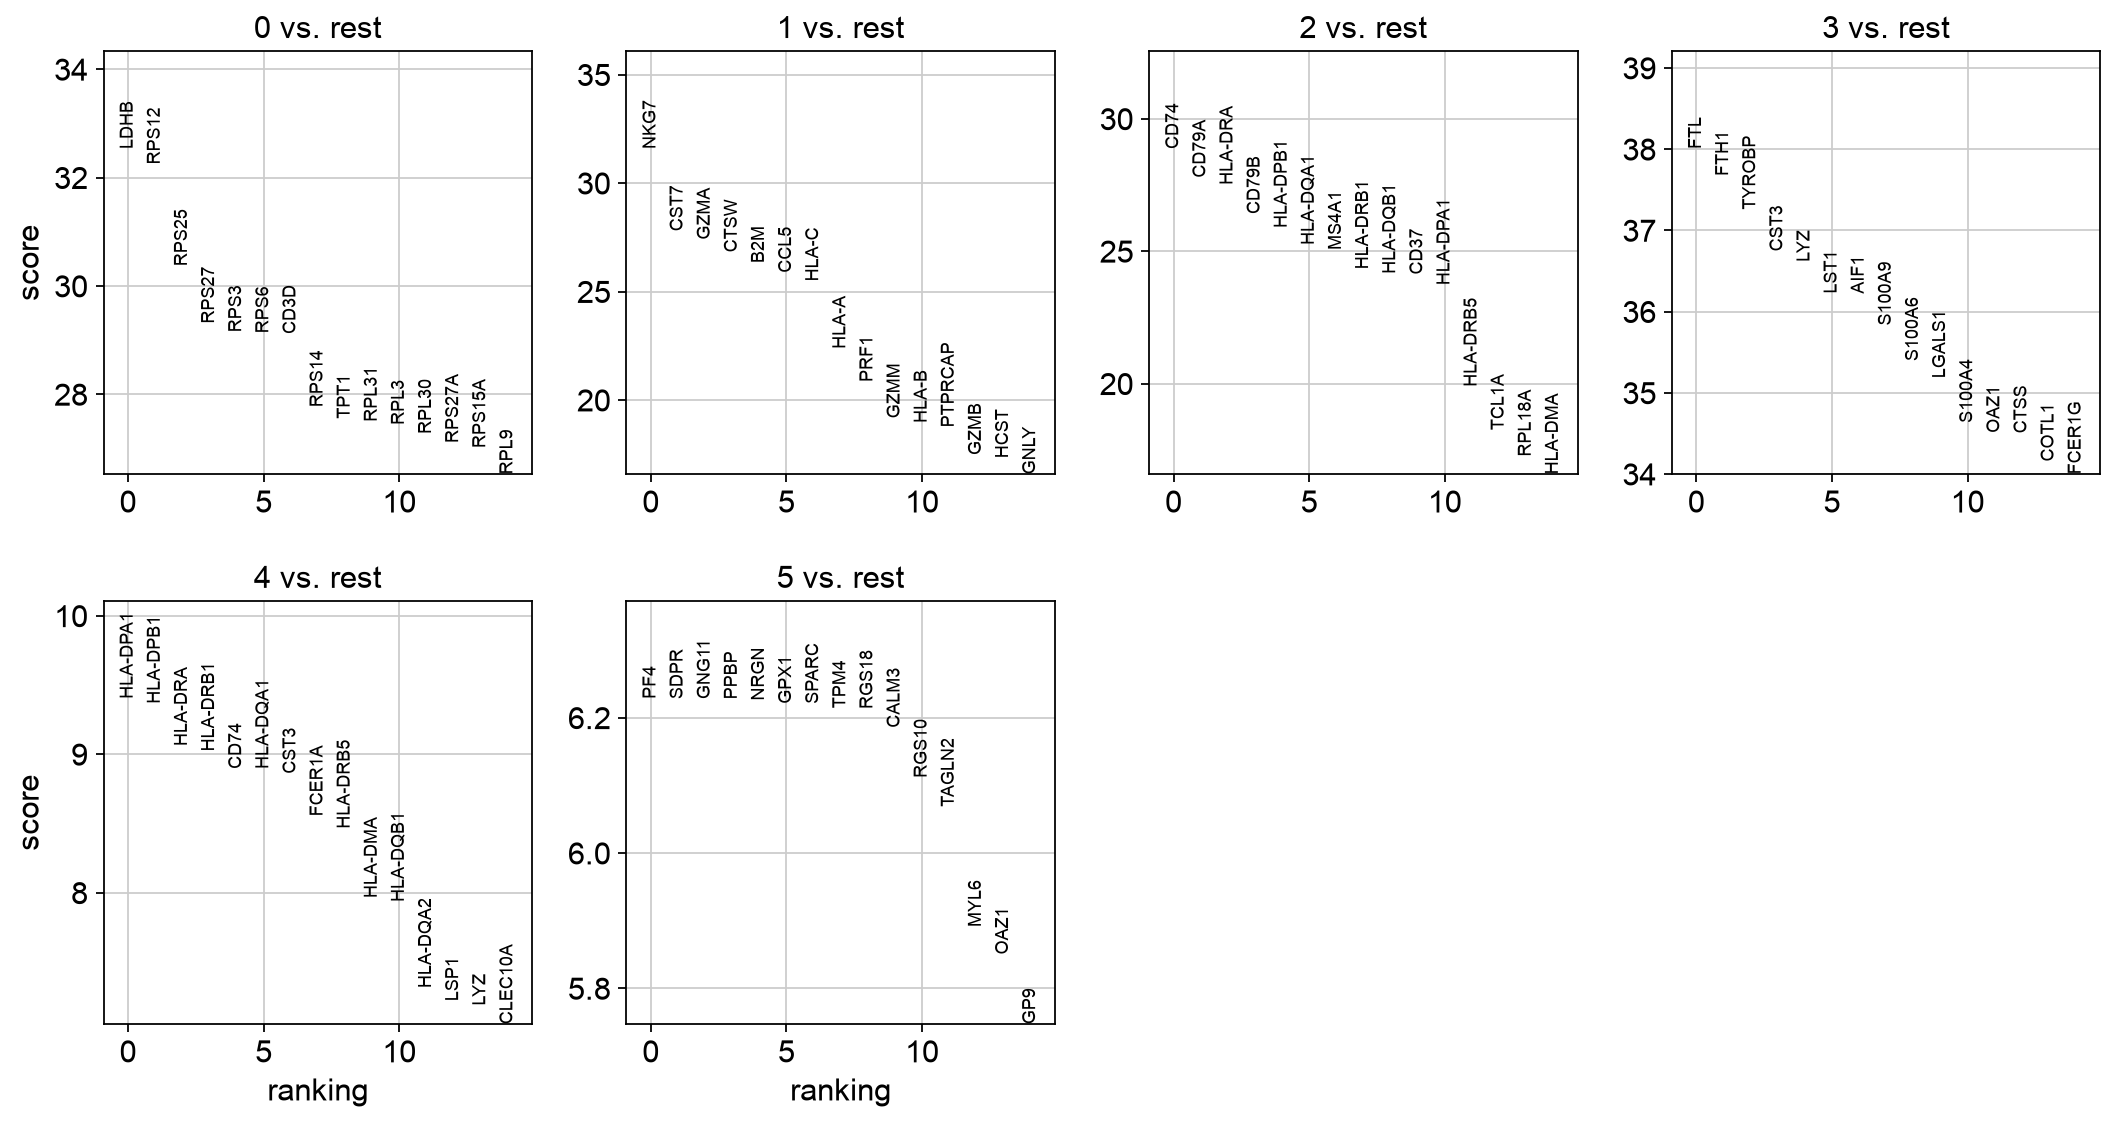

In [32]:
sc.tl.rank_genes_groups(adata, "leiden", method="wilcoxon")
sc.pl.rank_genes_groups(adata, n_genes=15, sharey=False)

Now compare the clusters against **canonical PBMC markers** you would recognize from immunology. In the dot plot, dot **size** is the fraction of cells expressing the gene and dot **color** is mean expression. A clean diagonal means the clusters line up with known cell types.

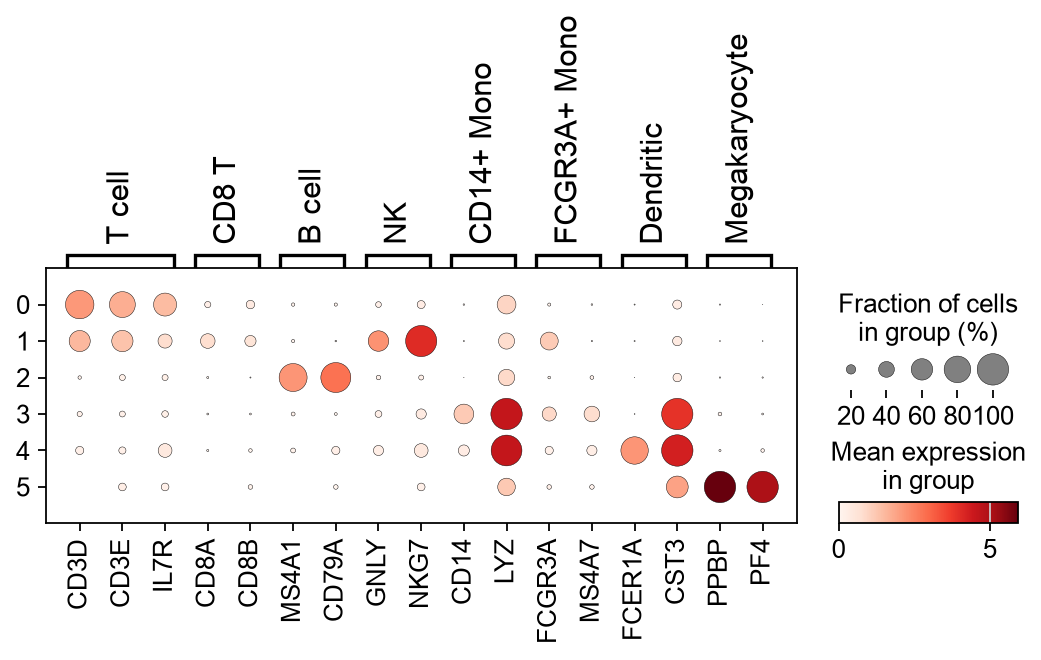

In [33]:
marker_genes = {
    "T cell": ["CD3D", "CD3E", "IL7R"],
    "CD8 T": ["CD8A", "CD8B"],
    "B cell": ["MS4A1", "CD79A"],
    "NK": ["GNLY", "NKG7"],
    "CD14+ Mono": ["CD14", "LYZ"],
    "FCGR3A+ Mono": ["FCGR3A", "MS4A7"],
    "Dendritic": ["FCER1A", "CST3"],
    "Megakaryocyte": ["PPBP", "PF4"],
}
sc.pl.dotplot(adata, marker_genes, groupby="leiden")

## Step 8 · Name the clusters

We assign each cluster the cell type whose marker set scores highest in it. This is **marker-driven annotation**, done transparently rather than by guessing cluster numbers.

> A cluster is not a cell type until you have earned the label. This automatic pass is a first draft: because several T-cell subsets share markers, expect CD4 vs CD8 calls to be approximate. Reading the markers yourself is the real skill — and the graded assignment asks you to.

In [34]:
marker_sets = {
    "CD4 T":        ["IL7R", "CD3D", "CD3E"],
    "CD8 T":        ["CD8A", "CD8B"],
    "B":            ["MS4A1", "CD79A", "CD79B"],
    "NK":           ["GNLY", "NKG7", "KLRD1"],
    "CD14+ Mono":   ["CD14", "LYZ", "S100A8"],
    "FCGR3A+ Mono": ["FCGR3A", "MS4A7"],
    "Dendritic":    ["FCER1A", "CST3"],
    "Megakaryocyte":["PPBP", "PF4"],
}
available = set(adata.raw.var_names)
score_cols = []
for name, genes in marker_sets.items():
    g = [x for x in genes if x in available]
    col = f"score_{name}"
    sc.tl.score_genes(adata, g, score_name=col, use_raw=True)
    score_cols.append(col)

mean_scores = adata.obs.groupby("leiden", observed=True)[score_cols].mean()
best = mean_scores.idxmax(axis=1).str.replace("score_", "", regex=False)
adata.obs["cell_type"] = adata.obs["leiden"].map(best.to_dict()).astype("category")

print(best.rename("assigned cell type"))

leiden
0            CD4 T
1               NK
2                B
3       CD14+ Mono
4        Dendritic
5    Megakaryocyte
Name: assigned cell type, dtype: object


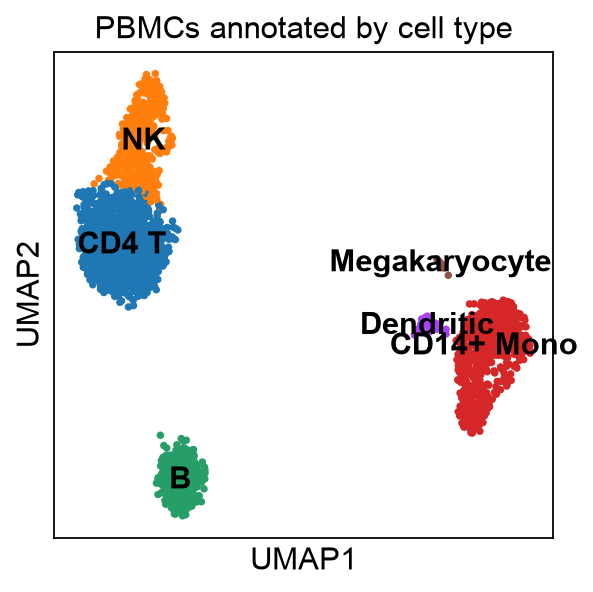

In [35]:
sc.pl.umap(adata, color="cell_type", legend_loc="on data",
           title="PBMCs annotated by cell type")

## Step 9 · Which cells express a given gene?

This is the payoff, and the question the whole module is built around. Color the same UMAP by a gene's expression and you can read off *which cell types* carry it — exactly what a bulk average cannot tell you.

Here we show three markers. In the graded notebook you will do this for **your own Part I target**.

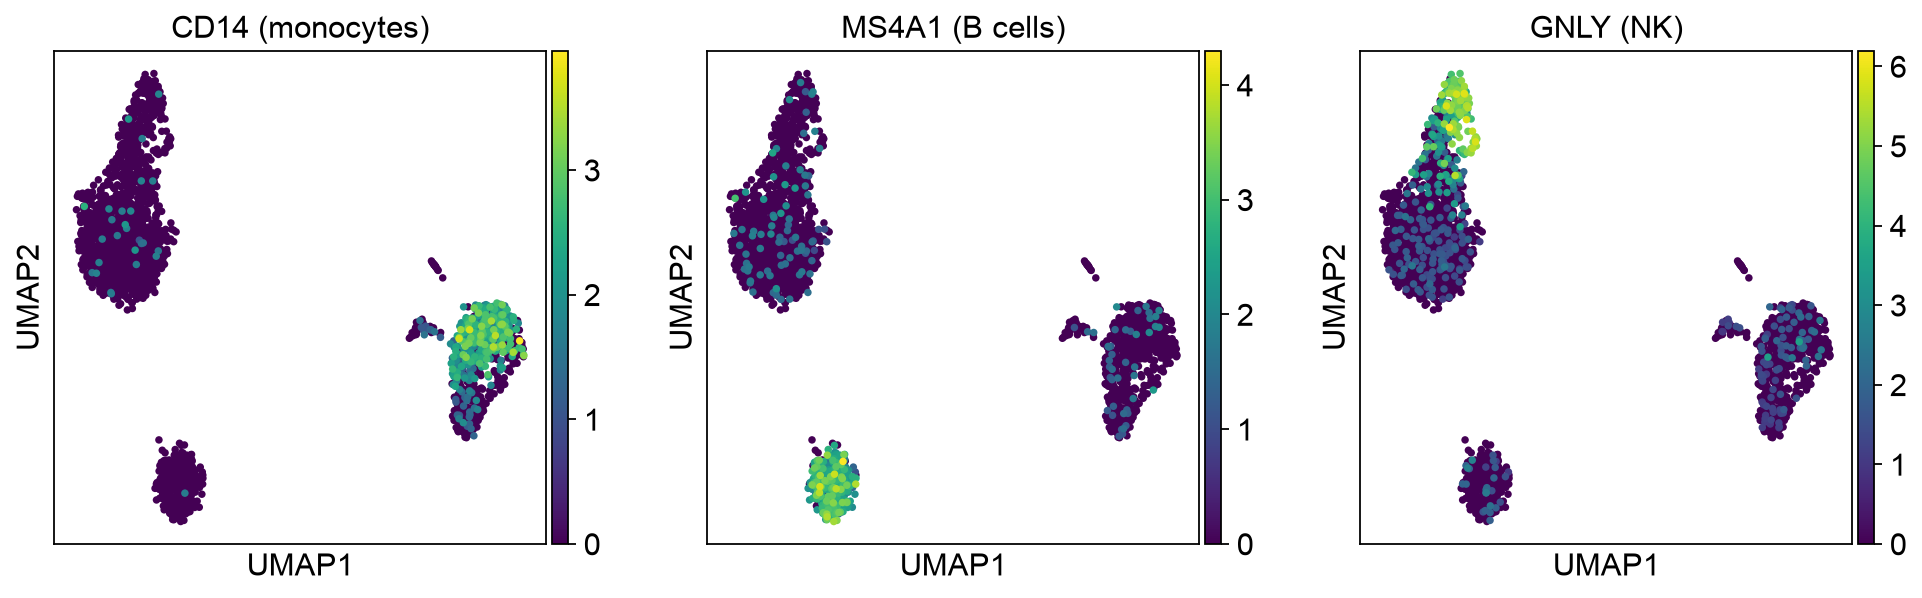

In [36]:
sc.pl.umap(adata, color=["CD14", "MS4A1", "GNLY"], use_raw=True,
           title=["CD14 (monocytes)", "MS4A1 (B cells)", "GNLY (NK)"])

## What you just saw

- A real count matrix became a labeled map of immune cell types: **QC → normalize → HVG → PCA → graph → Leiden → annotate**.
- The clusters were only numbers until **markers** gave them meaning.
- Coloring the map by a gene answered *which cells express it* — the thing bulk RNA-seq hides.

**Next:** the real-data notebook runs this same workflow on COVID-19 PBMCs pulled from the CZ CELLxGENE Census, adds **scVI** for batch integration (submitted as a GPU job on the Explorer cluster), and compares it against a foundation model. Then the graded assignment turns you loose on your own disease.